**Лабораторная работа №4**

**Исследование кривых обучения и регуляризации**

Для выполнения работы используется набор данных (датасет) с ценами на недвижимость в Бостоне (файл boston.csv). В наборе 506 выборок и 13 признаков. Цель - спрогнозировать стоимость дома по заданным характеристикам. Целевая переменная - MEDV (средняя стоимость частных домов в 1000 долларов).

Признаки: CRIM - уровень преступности на душу населения, ZN - доля земли под жилую застройку участков площадью более 25000 кв. футов, INDUS - доля акров, не относящихся к розничной торговле, CHAS - фиктивная переменная реки Чарльз, NOX - концентрация оксидов азота, RM - среднее количество комнат в доме, AGE - доля домов, построенных до 1940 года, DIS - взвешенное расстояние до пяти бостонских центров занятости, RAD - индекс доступности радиальных автомобильных дорог, TAX - ставка налога на имущество, PTRATIO - соотношение учеников и учителей, B - показатель, связанный с долей чернокожего населения, LSTAT - процент населения с более низким статусом.

**Описание задания к работе.**

1. Построить и отрисовать кривые обучения для любых 2х моделей - регрессоров.  
Сделать вывод - какая из моделей более подходит для предложенного датасета.  
Проанализировать наличие недо- или переобученности, выдвинуть предложение о значении целевого показателя выбранной метрики.  
Отрисовать целевое значение на построенном графике кривых обучения.  
Для одной из моделей отрисовать кривую обучения относительно ошибки.
2. Последовательно выполнить обучение моделей линейной регрессии, гребневой регуляризации (Ridge) и Lasso регуляризации.  
Сравнить модели используя несколько метрик.  
Свести значения весовых коэффициентов в единую таблицу, сделать выводы о коллинеарности данных и о важности имеющихся признаков
3. *Опциональное задание. Попытаться реализовать ElasticNet модель. Сравнить с результатами полученными в п.2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, learning_curve, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = pd.read_csv('boston.csv')
data

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


In [3]:
X = data.drop('MEDV', axis=1)
Y = data['MEDV']

### П.1. Кривые обучения (метрика R2)

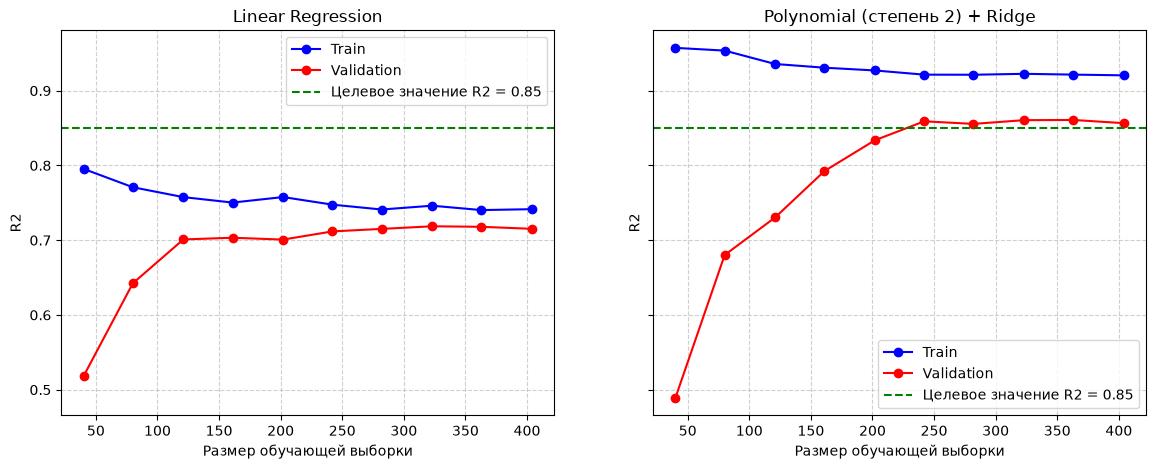

In [4]:
models = {
    'Linear Regression': LinearRegression(),
    'Polynomial (степень 2) + Ridge': make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), Ridge(alpha=10))
}
train_sizes = np.linspace(0.1, 1.0, 10)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
target_r2 = 0.85  # целевое значение R2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    sizes, train_scores, val_scores = learning_curve(
        model, X, Y, train_sizes=train_sizes, cv=cv, scoring='r2', shuffle=True, random_state=42
    )
    ax.plot(sizes, train_scores.mean(axis=1), color='blue', marker='o', label='Train')
    ax.plot(sizes, val_scores.mean(axis=1), color='red', marker='o', label='Validation')
    ax.axhline(target_r2, color='green', linestyle='--', label='Целевое значение R2 = %s' % target_r2)
    ax.set_title(name)
    ax.set_xlabel('Размер обучающей выборки')
    ax.set_ylabel('R2')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Кривая обучения относительно ошибки (MSE, Polynomial + Ridge)

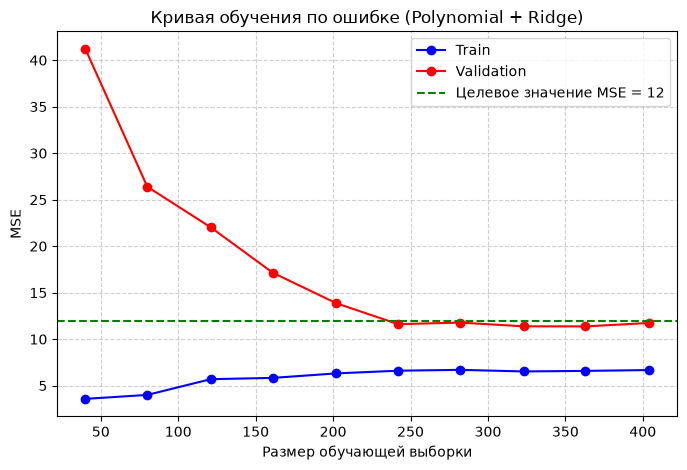

In [5]:
target_mse = 12  # целевое значение MSE

poly_model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), Ridge(alpha=10))

sizes, train_scores, val_scores = learning_curve(
    poly_model, X, Y, train_sizes=train_sizes, cv=cv,
    scoring='neg_mean_squared_error', shuffle=True, random_state=42
)

plt.figure(figsize=(8, 5))
plt.plot(sizes, -train_scores.mean(axis=1), color='blue', marker='o', label='Train')
plt.plot(sizes, -val_scores.mean(axis=1), color='red', marker='o', label='Validation')
plt.axhline(target_mse, color='green', linestyle='--', label='Целевое значение MSE = %s' % target_mse)
plt.xlabel('Размер обучающей выборки')
plt.ylabel('MSE')
plt.title('Кривая обучения по ошибке (Polynomial + Ridge)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Вывод по п.1:** у линейной регрессии кривые обучения и валидации сходятся на уровне $R^2$ около 0.72-0.74 и дальше не растут, MSE выходит на плато около 22. Это недообучение (высокое смещение): добавление данных не поможет, модель слишком проста для этих данных. Полиномиальная регрессия степени 2 с Ridge ($R^2$ на обучении около 0.92, на валидации около 0.86) заметно лучше: валидационная кривая превышает целевое значение $R^2$ = 0.85 начиная примерно с 240 объектов в обучающей выборке, а MSE на валидации около 11.7 при целевом значении 12 (на обучении около 6.7). Небольшой разрыв между кривыми (0.92 и 0.86) говорит о легком переобучении. Для этого датасета больше подходит полиномиальная регрессия, она единственная из двух достигает целевых значений $R^2$ = 0.85 и MSE = 12.

### П.2. Linear Regression, Ridge и Lasso

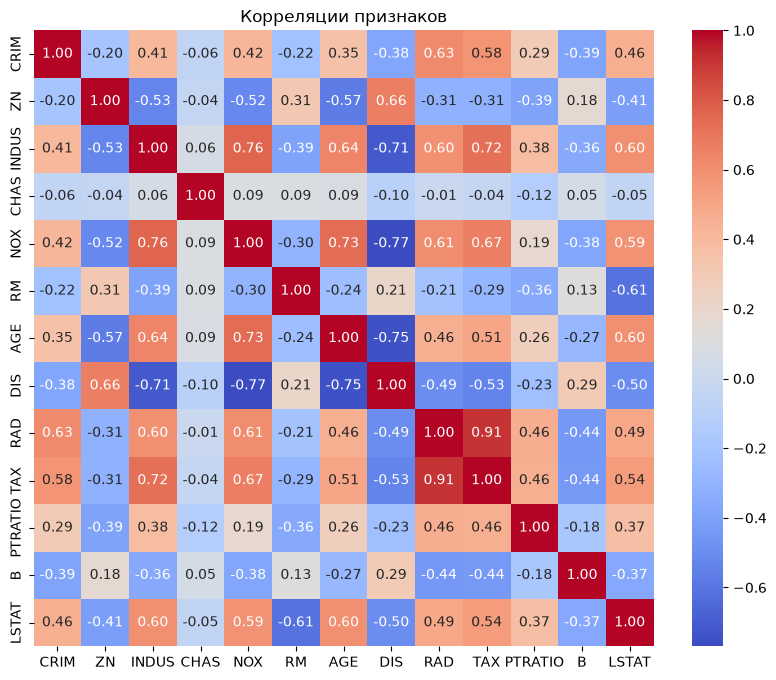

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляции признаков')
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

# масштабируем признаки, чтобы веса были сравнимы между собой
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [8]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=10),
    'Lasso': Lasso(alpha=0.2)
}

metrics_list = []
weights = pd.DataFrame(index=X.columns)

for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    weights[name] = model.coef_
    metrics_list.append({
        'Модель': name,
        'MAE': round(mean_absolute_error(y_test, y_pred), 4),
        'MSE': round(mean_squared_error(y_test, y_pred), 4),
        'R2': round(r2_score(y_test, y_pred), 4)
    })

metrics_df = pd.DataFrame(metrics_list)
metrics_df

,Модель,MAE,MSE,R2
0,Linear Regression,3.1627,21.5174,0.7112
1,Ridge,3.1518,21.8112,0.7073
2,Lasso,3.2803,23.8161,0.6804


In [9]:
weights.round(4)

,Linear Regression,Ridge,Lasso
CRIM,-1.1083,-1.0086,-0.5382
ZN,0.8084,0.6537,0.1419
INDUS,0.3431,0.1301,-0.0000
CHAS,0.8139,0.8556,0.7795
NOX,-1.7980,-1.4940,-0.7163
RM,2.9139,2.9537,3.0472
AGE,-0.2989,-0.3150,-0.0000
DIS,-2.9425,-2.5933,-1.4236
RAD,2.0942,1.4927,0.0000
TAX,-1.4471,-0.9537,-0.0000


### П.3. ElasticNet

In [10]:
en = ElasticNet(alpha=0.2, l1_ratio=0.5)
en.fit(X_train_s, y_train)
y_pred = en.predict(X_test_s)

weights['Elastic Net'] = en.coef_
metrics_list.append({
    'Модель': 'Elastic Net',
    'MAE': round(mean_absolute_error(y_test, y_pred), 4),
    'MSE': round(mean_squared_error(y_test, y_pred), 4),
    'R2': round(r2_score(y_test, y_pred), 4)
})

pd.DataFrame(metrics_list)

,Модель,MAE,MSE,R2
0,Linear Regression,3.1627,21.5174,0.7112
1,Ridge,3.1518,21.8112,0.7073
2,Lasso,3.2803,23.8161,0.6804
3,Elastic Net,3.2499,23.3995,0.6860


In [11]:
weights.round(4)

,Linear Regression,Ridge,Lasso,Elastic Net
CRIM,-1.1083,-1.0086,-0.5382,-0.6914
ZN,0.8084,0.6537,0.1419,0.2764
INDUS,0.3431,0.1301,-0.0000,-0.0712
CHAS,0.8139,0.8556,0.7795,0.8582
NOX,-1.7980,-1.4940,-0.7163,-0.8105
RM,2.9139,2.9537,3.0472,2.9806
AGE,-0.2989,-0.3150,-0.0000,-0.1762
DIS,-2.9425,-2.5933,-1.4236,-1.5096
RAD,2.0942,1.4927,0.0000,0.1832
TAX,-1.4471,-0.9537,-0.0000,-0.0966


**Итог:** Линейная регрессия и Ridge дали почти одинаковое качество ($R^2$ = 0.7112 и 0.7073), Lasso хуже ($R^2$ = 0.6804), ElasticNet между ними ($R^2$ = 0.6860). Регуляризация качество не улучшила: объектов (506) много относительно числа признаков (13), сильного переобучения нет. Коллинеарность видна по весам и корреляциям: RAD и TAX сильно коррелируют (0.91), у Ridge их веса уменьшились (RAD 2.09 -> 1.49, TAX -1.45 -> -0.95), а Lasso обнулил оба, а также INDUS и AGE. Самые важные признаки - LSTAT, RM, DIS, PTRATIO, их веса остаются большими при любой регуляризации, малозначимые - INDUS, AGE, TAX, RAD.